# Watermarking LLM-generated text from scratch: the Green-Red list method

In August 2026 Anthropic announced that new Claude models will watermark the text they generate, using a version of Google DeepMind's SynthID-Text ([TechCrunch](https://techcrunch.com/2026/08/15/anthropic-shares-more-details-about-how-claudes-new-watermarks-will-work/)). Google has watermarked Gemini text with SynthID-Text since 2024 ([Dathathri et al., *Nature*, 2024](https://www.nature.com/articles/s41586-024-08025-4)). The transparency rules of the EU AI Act are one of the drivers. Text watermarking has moved from research papers into production systems.

In this post we build a text watermark from scratch with the method that started this line of work: the "Green-Red list" method of Kirchenbauer et al. (2023), [*A Watermark for Large Language Models*](https://arxiv.org/abs/2301.10226). SynthID-Text belongs to a related but different branch. Kirchenbauer's method *shifts the model's probabilities* toward some tokens. SynthID-Text keeps the probabilities and instead *replaces the source of randomness* used to sample from them (tournament sampling), which is how it avoids hurting text quality. Both share one core idea: **a secret key plus the recent context decide, pseudo-randomly, which choices carry the mark.** We will cover SynthID-Text in a some follow-up post.

**Roadmap**

1. **Baseline.** Implement the method with a one-token context, look at the watermark token by token, and see why a naive detection rule fails.
2. **Statistics.** Turn detection into a proper hypothesis test: z-score, CLT, p-values.
3. **The knobs.** How the bias δ, the green fraction γ and the model's entropy trade text quality against detectability.
4. **Attacks.** Build one evaluation harness with three kinds of edits, from random noise to a full LLM paraphrase.
5. **Context schemes.** Change *only* the rule that turns context into a seed, run every variant through the same harness, and measure the robustness-versus-security trade-off.
6. **Limitations and outlook.**

Every comparison in Parts 3–5 uses the same prompts, random seeds, sampling settings, text length, γ and δ, so any difference you see comes from the one thing we changed.

## How the method works

```mermaid
flowchart LR
  subgraph GEN["Generation: needs the model"]
    A["Previous h tokens"] --> B["Keyed PRF, secret key K"]
    B --> C["Seed for a PRNG that permutes the vocabulary"]
    C --> D["Green list G: fraction γ of the vocabulary. Red list R: the rest"]
    E["Model logits"] --> F["Add δ to every green logit"]
    D --> F
    F --> H["Softmax, sample next token"]
    H -->|"append and repeat"| A
  end
  subgraph DET["Detection: needs only K and the tokenizer"]
    I["Suspect text"] --> J["Tokenize"]
    J --> K2["Rebuild G at every position"]
    K2 --> L["Count green tokens"]
    L --> M["z-score, p-value, decision"]
  end
```
<img src="blog/imgs/watermark_flow.png" width="600">

**Notation.** $V$ is the vocabulary, $s_t$ the token at step $t$, $\ell_k$ the model's logit for token $k$, $h$ the context width, $K$ the secret key.

### Step 1: Partition the vocabulary

Before the model picks token $s_t$, the algorithm looks at the previous $h$ tokens ($h=1$ in the basic version of [the paper](https://arxiv.org/abs/2301.10226)). A keyed pseudo-random function turns that context into a seed:

$$\text{seed}_t = \mathrm{PRF}_K(s_{t-h}, \dots, s_{t-1})$$

The seed drives a pseudo-random number generator that shuffles the vocabulary. The first $\gamma|V|$ tokens of the shuffle form the **green list** $G_t$; the rest form the **red list** $R_t$. The hash function and the PRNG can be completely public. **Only the key $K$ is secret**: anyone who has it can recompute every green list; anyone who doesn't sees ordinary text. Because the seed depends on the context, the partition changes at almost every step. Common choices are $\gamma = 0.25$ or $\gamma = 0.5$; we use $0.5$.

### Step 2: Shift the distribution

The model produces a logit for every token. Before the softmax, the algorithm adds a constant $\delta$ (the watermark strength) to the logit of every green token:

$$
\tilde{\ell}_k =
\begin{cases}
\ell_k + \delta & \text{if } k \in G_t \\
\ell_k & \text{if } k \in R_t
\end{cases}
\qquad\Longrightarrow\qquad
\tilde{p}_k = \frac{e^{\ell_k + \delta\,\mathbb{1}[k \in G_t]}}{\sum_{j \in V} e^{\ell_j + \delta\,\mathbb{1}[j \in G_t]}}
$$

**Red tokens are not forbidden.** [The paper](https://arxiv.org/abs/2301.10226) first presents a *hard* rule that bans red tokens completely, then replaces it with this *soft* rule, because banning tokens destroys text whenever the only sensible next token happens to be red. With the soft rule, a red token still wins whenever its logit is more than $\delta$ above the best green one.

**Why a soft shift works.** When the model is very confident (**low entropy**: one token holds almost all the probability), a red token with a much larger logit than every green token still gets picked with high probability. The watermark steps aside and the text stays correct. When the model is uncertain (**high entropy**: several synonyms are about equally likely), the bias tilts the choice toward the green synonym. The watermark therefore lives in the high-entropy positions of the text.

**The trade-off.** Two goals pull against each other: *fluency* (don't override the model's preferred word) and *detectability* (put as many green tokens in the text as possible). In the best case for the watermark, a position where the model's probability is spread evenly, the chance of picking a green token is

$$P(\text{green}) = \frac{\gamma e^{\delta}}{\gamma e^{\delta} + 1 - \gamma},$$

which for $\gamma = 0.5$ is about 73% at $\delta = 1$, 88% at $\delta = 2$ and 98% at $\delta = 4$. At low-entropy positions it stays close to what the model wanted anyway. A larger $\delta$ gives stronger evidence per token but overrides the model more often, so quality drops. Low-entropy text (code, facts, lists) carries little watermark whatever $\delta$ we choose. Part 3 measures both effects.

### Step 3: Detect

The detector needs **the key and the tokenizer, not the language model**. It re-tokenizes the suspect text, rebuilds $G_t$ at every position from the preceding tokens, and counts how many tokens are green. In text written without the key, each token lands in its green list with probability $\gamma$, so about half of them are green. Watermarked text has too many green tokens. Deciding how many is "too many" is a statistics question, and Part 2 answers it.

## Setup

```bash
pip install "transformers>=5.0" torch nltk scipy pandas matplotlib
```

Generation dominates the runtime. On a GPU the whole notebook runs in minutes; on a CPU a 2B model is much slower, so start with `QUICK_RUN = True`. Generations are cached on disk (`CACHE_DIR`), so re-running a plotting cell never regenerates text.

In [1]:
import difflib
import hashlib
import html
import math
import os
import pickle
import random
import re
from collections import OrderedDict

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from scipy.stats import binom, binomtest, norm
from transformers import AutoModelForCausalLM, AutoTokenizer, LogitsProcessor, LogitsProcessorList

In [2]:
# ---------------- Configuration ----------------
MODEL_NAME = "openbmb/MiniCPM5-2B"
SECRET_KEY = b"do93jfnia92jvidf02"   # the ONLY secret of the scheme (max 64 bytes)
SEED = 1234

QUICK_RUN = False          # True = small settings for a fast first pass (results are noisy: 3 prompts)
USE_CACHE = True
CACHE_DIR = "wm_cache"
RUN_LLM_PARAPHRASE = True  # the paraphrase attack costs one extra generation per text
BATCH_SIZE = 16            # texts generated in parallel; lower it if you run out of GPU memory

GAMMA = 0.5                # green-list fraction, fixed in every comparison
DELTA = 2.0                # watermark strength, fixed in every comparison (Part 3 sweeps it)
Z_THRESHOLD = 4.0          # one-sided p ≈ 3.2e-5
MIN_SCORED_TOKENS = 16     # below this we refuse to decide

# Pure multinomial sampling, as in the paper. The watermark processor runs *before*
# temperature / top-p in transformers, so with temperature T the effective bias is δ/T.
SAMPLING = dict(do_sample=True, temperature=1.0, top_p=0.95, top_k=0)
GREEDY = dict(do_sample=False, temperature=None, top_p=None, top_k=None)

if QUICK_RUN:
    N_PROMPTS, MAX_NEW_TOKENS, N_HUMAN, N_LONG, LONG_TOKENS = 3, 80, 10, 1, 150
    DELTAS, RATES, HEATMAP_LENGTHS, N_EDITS = [1.0, 2.0, 4.0], [0.0, 0.3, 0.7], [25, 50, 80], 20
else:
    N_PROMPTS, MAX_NEW_TOKENS, N_HUMAN, N_LONG, LONG_TOKENS = 10, 200, 50, 3, 500
    DELTAS, RATES, HEATMAP_LENGTHS, N_EDITS = [0.5, 1.0, 2.0, 4.0], [0.0, 0.1, 0.2, 0.3, 0.5, 0.7], [25, 50, 100, 150, 200], 100

PROMPTS = [
    "The future of artificial intelligence will bring",
    "Deep learning architectures have revolutionized the field of computer vision by allowing",
    "The integration of machine learning into modern software engineering practices has altered",
    "Advancements in cloud computing architectures have allowed modern corporations to scale",
    "The history of the printing press shows that",
    "When planning a long hiking trip in the mountains, the most important thing is",
    "Coffee has been part of daily life for centuries because",
    "Urban gardens are becoming popular in large cities since",
    "The main challenge for renewable energy today is",
    "A good teacher is someone who",
][:N_PROMPTS]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16 if DEVICE == "cuda" else torch.float32
os.makedirs(CACHE_DIR, exist_ok=True)

In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE).to(DEVICE).eval()

# The watermark must use the size of the logit vector, which can differ from len(tokenizer)
VOCAB_SIZE = model.get_output_embeddings().weight.shape[0]
if tokenizer.pad_token is None:  # batched generation needs a padding token
    tokenizer.pad_token = tokenizer.eos_token
PAD_ID = tokenizer.pad_token_id
_eos = model.generation_config.eos_token_id
EOS_IDS = set(_eos if isinstance(_eos, list) else [_eos])
print(f"vocab (logits): {VOCAB_SIZE:,} | len(tokenizer): {len(tokenizer):,} | device: {DEVICE}")

for pkg in ["wordnet", "omw-1.4", "brown", "stopwords", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

Loading weights:   0%|          | 0/381 [00:00<?, ?it/s]

vocab (logits): 130,560 | len(tokenizer): 130,560 | device: cpu


### NLTK data packages - for whah we need it

The `nltk` library ships only code; corpora, word lists and trained models are separate data packages. The loop above downloads them once into a local folder (usually `~/nltk_data`) and skips packages that are already present.

| Package | What it is | Used for |
|---|---|---|
| `brown` | The Brown corpus: about one million words of American English from the 1960s | Human-written texts for the null distribution and false-alarm tests (`load_human_texts`) |
| `wordnet` | A dictionary of English words grouped into synonym sets | Both word-replacement attacks (`wn.synsets`, lemma names) |
| `omw-1.4` | Open Multilingual WordNet, extra data that accompanies WordNet | Not used directly; some NLTK versions expect it next to WordNet |
| `stopwords` | Lists of very common words ("the", "is", "of") | The synonym swap skips these words |
| `averaged_perceptron_tagger_eng` | A trained part-of-speech tagger | `nltk.pos_tag` in the synonym swap, which only replaces singular nouns, adjectives and adverbs |
| `averaged_perceptron_tagger` | The same tagger under its pre-3.9 name | Compatibility with older NLTK versions |

In [4]:
from nltk.corpus import brown
from nltk.tokenize.treebank import TreebankWordDetokenizer

def load_human_texts(n: int, n_tokens: int) -> list[str]:
    # Human-written texts from the Brown corpus, each cut to exactly n_tokens tokens
    detok = TreebankWordDetokenizer()
    texts, buffer = [], ""
    for para in brown.paras():
        buffer = (buffer + " " + " ".join(detok.detokenize(sent) for sent in para)).strip()
        ids = tokenizer.encode(buffer, add_special_tokens=False)
        if len(ids) >= n_tokens:
            texts.append(tokenizer.decode(ids[:n_tokens]))
            buffer = ""
            if len(texts) == n:
                break
    return texts

HUMAN_TEXTS = load_human_texts(N_HUMAN, MAX_NEW_TOKENS)
print(f"{len(HUMAN_TEXTS)} human texts, e.g.:\n{HUMAN_TEXTS[0][:300]}...")

50 human texts, e.g.:
The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced "no evidence" that any irregularities took place. The jury further said in term-end presentments that the City Executive Committee, which had over-all charge of the election, "deserves the praise ...


# Part 1: The baseline

## 1.1 The keyed pseudo-random function and the green lists

We need a function that maps a context and a secret key to a seed. A common shortcut is `previous_token ^ key`, but XOR with a constant is trivially reversible and maps neighbouring token ids to neighbouring seeds. We use a real keyed hash instead: BLAKE2b has a built-in key parameter, so `blake2b(data, key=K)` is a proper keyed PRF (a MAC). The seed then drives `torch.randperm`, and the first $\gamma|V|$ tokens of the permutation are green.

The rule that turns context into a seed is the part we will vary in Part 5, so we give it its own small class. The baseline is `LeftHash`: the seed depends only on the previous token ($h = 1$).

In [5]:
def prf(*values: int) -> int:
    # Keyed pseudo-random function: 64-bit BLAKE2b digest keyed with SECRET_KEY
    # int to bytes
    data = b"".join(int(v).to_bytes(8, "little", signed=True) for v in values)
    # Hashes the bytes -> keyed hash (MAC) -> back to int 
    return int.from_bytes(hashlib.blake2b(data, key=SECRET_KEY, digest_size=8).digest(), "little")


class GreenListGenerator:
    # Maps a seed to a boolean mask over the vocabulary (True = green). Small LRU cache for speed.
    def __init__(self, vocab_size: int, gamma: float, cache_size: int = 256):
        self.vocab_size, self.gamma = vocab_size, gamma
        self.green_size = int(gamma * vocab_size)
        self._cache, self._cache_size = OrderedDict(), cache_size

    def mask(self, seed: int) -> torch.Tensor:
        seed %= 2**63
        if seed in self._cache:
            self._cache.move_to_end(seed)
            return self._cache[seed]
        # Leaves the global generator untouched and perserve reproducibility
        generator = torch.Generator().manual_seed(seed)
        perm = torch.randperm(self.vocab_size, generator=generator)
        mask = torch.zeros(self.vocab_size, dtype=torch.bool)
        mask[perm[: self.green_size]] = True
        self._cache[seed] = mask
        if len(self._cache) > self._cache_size:
            self._cache.popitem(last=False)
        # Returns a boolean tensor with one entry per vocabulary token, True means green
        return mask


class SeedingScheme:
    # Turns the last `context_width` token ids into a seed
    name = "base"
    context_width = 1   # h value
    needs_model = False  # True if the detector also needs the model's embeddings

    def seed(self, context: list[int]) -> int:
        raise NotImplementedError

# Looks at one previous token (context_width = 1) and hashes it: prf(context[-1]),
# where context[-1] is the last token id of the context
class LeftHash(SeedingScheme):
    name = "LeftHash h=1"
    context_width = 1

    def seed(self, context):
        return prf(context[-1])

## 1.2 The logits processor

Hugging Face `generate()` calls every `LogitsProcessor` once per generated token. Ours recomputes the green list from the context and adds $\delta$ to the green logits. It can also log the entropy of the model's original distribution at each step; we will use that in Part 3.

In [6]:
class WatermarkLogitsProcessor(LogitsProcessor):
    def __init__(self, scheme: SeedingScheme, gamma: float = GAMMA, delta: float = DELTA):
        self.scheme, self.gamma, self.delta = scheme, gamma, delta
        self.greens = GreenListGenerator(VOCAB_SIZE, gamma)
        self.entropy_log = None  # set to one empty list per batch row to record per-step entropy

    @property
    def cache_id(self) -> str:
        key_id = hashlib.sha1(SECRET_KEY).hexdigest()[:8]
        return f"{self.scheme.name}|gamma={self.gamma}|delta={self.delta}|key={key_id}"

    def __call__(self, input_ids: torch.LongTensor, scores: torch.FloatTensor) -> torch.FloatTensor:
        assert scores.shape[-1] == self.greens.vocab_size, "logit size and green-list size differ"
        h = self.scheme.context_width
        contexts = input_ids[:, -h:].tolist()  # one device-to-host copy for the whole batch
        # Build the green list
        green = torch.stack([self.greens.mask(self.scheme.seed(c)) for c in contexts]).to(scores.device)
        if self.entropy_log is not None:    # Record entropy
            logp = torch.log_softmax(scores.float(), dim=-1)
            for row_log, e in zip(self.entropy_log, (-(logp.exp() * logp).nansum(dim=-1)).tolist()):
                row_log.append(e)
        # Apply the watermark
        return scores + self.delta * green.to(scores.dtype)

## 1.3 Generation

`generate_many` returns the prompt ids, the completion ids and the completion text separately. **The detector only ever sees the completion text**, because in practice nobody hands you the prompt. We fix the output length with `min_new_tokens = max_new_tokens` so that every text in a comparison has the same number of tokens.

Generating one text at a time leaves most of a GPU idle, so prompts are generated in batches of `BATCH_SIZE`. Two details make batching work for a decoder-only model:

* **Left padding.** Shorter prompts are padded on the left, so every row ends with its real last token and generation continues directly from it. The attention mask tells the model to ignore the padding, and since padding is only ever on the left, the last $h$ tokens the watermark looks at are always real tokens.
* **Per-text results from a shared batch.** Each row is cut at its own length limit and at its first end-of-sequence token, and each text is cached separately.

`generate` is kept as a one-prompt wrapper. One caveat: all rows in a batch share one random stream, so a text generated in a batch differs from the text the same prompt and seed would give on its own. Results are still reproducible for the same prompts, order and `BATCH_SIZE`, and the cache makes re-runs identical.

In [7]:
def _cache_path(key) -> str:
    return os.path.join(CACHE_DIR, hashlib.sha1(repr(key).encode()).hexdigest() + ".pkl")


def _generate_batch(prompts: list[str], processor, caps: list[int], seed: int, sampling: dict,
                    force_length: bool, add_special_tokens: bool) -> list[dict]:
    set_seed(seed)
    enc = tokenizer(prompts, return_tensors="pt", padding=True, padding_side="left",
                    add_special_tokens=add_special_tokens).to(model.device)
    n = max(caps)
    if processor is not None:
        processor.entropy_log = [[] for _ in prompts]
    with torch.no_grad():
        out = model.generate(
            **enc,
            max_new_tokens=n,
            min_new_tokens=n if force_length else None,
            logits_processor=LogitsProcessorList([processor]) if processor else None,
            pad_token_id=PAD_ID,
            **sampling,
        )
    width = enc["input_ids"].shape[1]
    results = []
    for row, (prompt, cap) in enumerate(zip(prompts, caps)):
        prompt_ids = enc["input_ids"][row][enc["attention_mask"][row].bool()].tolist()  # drop left padding
        completion_ids = out[row, width:].tolist()[:cap]
        for j, tok in enumerate(completion_ids):  # finished rows are padded; keep up to the first EOS
            if tok in EOS_IDS:
                completion_ids = completion_ids[:j + 1]
                break
        results.append(dict(prompt=prompt, prompt_ids=prompt_ids, ids=completion_ids,
                            text=tokenizer.decode(completion_ids, skip_special_tokens=True),
                            entropies=processor.entropy_log[row][:len(completion_ids)] if processor else None))
    if processor is not None:
        processor.entropy_log = None
    return results


def generate_many(prompts: list[str], processor: WatermarkLogitsProcessor | None = None,
                  max_new_tokens: int | list[int] = MAX_NEW_TOKENS, seeds: list[int] | None = None,
                  sampling: dict | None = None, force_length: bool = True, add_special_tokens: bool = True,
                  batch_size: int = BATCH_SIZE) -> list[dict]:
    sampling = SAMPLING if sampling is None else sampling
    seeds = [SEED + i for i in range(len(prompts))] if seeds is None else list(seeds)
    caps = [max_new_tokens] * len(prompts) if isinstance(max_new_tokens, int) else list(max_new_tokens)
    keys = [(MODEL_NAME, p, processor.cache_id if processor else "no-watermark", cap, s,
             sorted(sampling.items()), force_length, add_special_tokens)
            for p, cap, s in zip(prompts, caps, seeds)]

    results, todo = [None] * len(prompts), []
    for i, key in enumerate(keys):
        path = _cache_path(key)
        if USE_CACHE and os.path.exists(path):
            with open(path, "rb") as f:
                results[i] = pickle.load(f)
        else:
            todo.append(i)

    for start in range(0, len(todo), batch_size):
        idx = todo[start:start + batch_size]
        batch = _generate_batch([prompts[i] for i in idx], processor, [caps[i] for i in idx], seeds[idx[0]],
                                sampling, force_length, add_special_tokens)
        for i, result in zip(idx, batch):
            results[i] = result
            with open(_cache_path(keys[i]), "wb") as f:
                pickle.dump(result, f)
    return results


def generate(prompt: str, processor: WatermarkLogitsProcessor | None = None, max_new_tokens: int = MAX_NEW_TOKENS,
             seed: int = SEED, **kwargs) -> dict:
    return generate_many([prompt], processor, max_new_tokens, seeds=[seed], **kwargs)[0]

## 1.4 Seeing the watermark

`score_tokens` replays the detector: for every token that has a full context window inside the text, it rebuilds the green list and records whether the token is green. `show_colored` paints the result, so we can literally see the watermark. Grey tokens are the prompt (or the first $h$ tokens of a text), which are not scored.

In [8]:
def score_tokens(ids: list[int], processor: WatermarkLogitsProcessor) -> tuple[list[bool], list[tuple]]:
    # Green flag for every position t >= h, plus the (context, token) pair used to deduplicate
    h = processor.scheme.context_width
    flags, pairs = [], []
    for t in range(h, len(ids)):
        context = ids[t - h:t]
        seed = processor.scheme.seed(context)
        flags.append(bool(processor.greens.mask(seed)[ids[t]]))
        pairs.append((tuple(context), ids[t]))
    return flags, pairs


def show_colored(ids: list[int], processor: WatermarkLogitsProcessor, n_unscored: int | None = None, title: str = ""):
    h = processor.scheme.context_width
    n_unscored = h if n_unscored is None else max(n_unscored, h)
    flags, _ = score_tokens(ids, processor)
    special = set(tokenizer.all_special_ids)
    spans = []
    for t, tok in enumerate(ids):
        if tok in special:
            continue  # e.g. the BOS token <s>
        piece = html.escape(tokenizer.decode([tok])).replace("\n", "<br>")
        if t < n_unscored:
            color = "#d9d9d9"
        else:
            color = "#9be39b" if flags[t - h] else "#f4a3a3"
        spans.append(f'<span style="background:{color};color:#111;border-radius:3px">{piece}</span>')
    scored = flags[n_unscored - h:]
    summary = f"{sum(scored)}/{len(scored)} scored tokens are green ({sum(scored) / max(len(scored), 1):.0%})"
    display(HTML(f"<b>{html.escape(title)}</b> {summary}<div style='line-height:1.9;font-family:sans-serif'>{''.join(spans)}</div>"))

In [9]:
baseline = WatermarkLogitsProcessor(LeftHash(), gamma=GAMMA, delta=DELTA)

demo_prompt = PROMPTS[0]
wm_demo = generate(demo_prompt, baseline, seed=SEED)
plain_demo = generate(demo_prompt, None, seed=SEED)

show_colored(wm_demo["prompt_ids"] + wm_demo["ids"], baseline, n_unscored=len(wm_demo["prompt_ids"]),
             title=f"Watermarked (δ={DELTA}):")
show_colored(plain_demo["prompt_ids"] + plain_demo["ids"], baseline, n_unscored=len(plain_demo["prompt_ids"]),
             title="No watermark:")

## 1.5 A first, deliberately naive detector

The obvious rule: count the green tokens and call the text watermarked if more than 70% are green. We implement it on purpose, because seeing exactly how it fails motivates the rest of Part 1 and all of Part 2.

In [10]:
def naive_detect(text: str, processor: WatermarkLogitsProcessor, threshold: float = 0.7) -> dict:
    ids = tokenizer.encode(text, add_special_tokens=False)
    flags, _ = score_tokens(ids, processor)
    ratio = sum(flags) / len(flags)
    return dict(scored=len(flags), green_ratio=round(ratio, 3), is_watermarked=ratio > threshold)

print("Watermarked :", naive_detect(wm_demo["text"], baseline))
print("No watermark:", naive_detect(plain_demo["text"], baseline))

Watermarked : {'scored': 199, 'green_ratio': 0.734, 'is_watermarked': True}
No watermark: {'scored': 199, 'green_ratio': 0.568, 'is_watermarked': False}


## 1.6 Why the naive rule fails

A fixed ratio threshold has two problems.

1. **It ignores δ.** The expected green ratio depends on δ, γ and the entropy of the text. With δ = 1 even a perfectly uncertain model picks green only 73% of the time, and real text mixes in many low-entropy positions, so a 0.7 threshold will almost never fire.
2. **It ignores length.** With 10 scored tokens, a text needs 8 green tokens to beat 70%, and an unwatermarked text gets there by pure chance 5.5% of the time: roughly one false alarm in 18 short texts. Over 500 tokens, 70% green essentially never happens by chance, and even 59% is already strong evidence (Part 2). The evidence depends on *how many* tokens we saw, and a ratio throws that information away.

The next two cells show both problems on real text.

In [11]:
# Problem 1: weak watermark (δ = 1) against the 0.7 threshold
weak = WatermarkLogitsProcessor(LeftHash(), gamma=GAMMA, delta=1.0)
rows = []
for label, proc in [("δ=1.0", weak), (f"δ={DELTA}", baseline)]:
    for g in generate_many(PROMPTS, proc):
        rows.append(dict(setting=label, **naive_detect(g["text"], proc)))
naive_df = pd.DataFrame(rows)
naive_df.groupby("setting").agg(mean_green_ratio=("green_ratio", "mean"), detection_rate=("is_watermarked", "mean"))

,mean_green_ratio,detection_rate
setting,,
δ=1.0,0.5910,0.0
δ=2.0,0.7101,0.6


Every text in this experiment is watermarked, so the correct detection rate is 100% in both rows. With δ = 1 the texts are 59% green on average, clearly above the 50% expected without a watermark, yet the 70% rule catches none of them: even a completely undecided model picks green only 73% of the time at δ = 1, and a confident model stays far below that. With δ = 2 the average of 71% sits right at the threshold, so the rule catches 6 of 10 texts, essentially a coin toss. A fixed ratio threshold can only be tuned to one watermark strength and one model.

In [12]:
# Problem 2: short human snippets pass the 0.7 threshold by chance
snippet_len = 10
k_min = math.floor(0.7 * snippet_len) + 1  # smallest green count with ratio > 0.7
print(f"Theory: beating 70% needs >= {k_min} of {snippet_len} green; by chance P = {binom.sf(k_min - 1, snippet_len, GAMMA):.1%}")

snippets = []
for text in HUMAN_TEXTS:
    ids = tokenizer.encode(text, add_special_tokens=False)
    for start in range(0, len(ids) - snippet_len - 1, snippet_len + 1):
        snippets.append(tokenizer.decode(ids[start:start + snippet_len + 1]))  # +1: the first token is context only
false_alarms = np.mean([naive_detect(s, baseline)["is_watermarked"] for s in snippets])
print(f"Empirical: {false_alarms:.1%} of {len(snippets)} ten-token human snippets are flagged as watermarked")

Theory: beating 70% needs >= 8 of 10 green; by chance P = 5.5%
Empirical: 5.3% of 900 ten-token human snippets are flagged as watermarked


5.3% of 900 ten-token human snippets were flagged as watermarked, matching the binomial prediction of 5.5%: about one false accusation in every 18 short human texts.\
A ratio treats 7 of 10 and 350 of 500 as the same 70%, although only the second is strong evidence; the z-score in Part 2 takes the number of tokens into account.

# Part 2: Detection as a hypothesis test

**Null hypothesis $H_0$:** the text was written without knowledge of the key $K$ (by a human, or by a model without our watermark).

Under $H_0$, the green list at each position is a pseudo-random subset of size $\gamma|V|$ that the writer knows nothing about, so each scored token is green with probability $\gamma$. If we also assume the positions are independent, the number of green tokens $|s|_G$ among $T$ scored tokens follows a binomial distribution:

$$|s|_G \sim \mathrm{Binomial}(T, \gamma), \qquad \mathbb{E}\,|s|_G = \gamma T, \qquad \mathrm{Var}\,|s|_G = T\gamma(1-\gamma).$$

By the central limit theorem (for the binomial, the de Moivre–Laplace theorem), the standardized count is approximately standard normal for large $T$:

$$z = \frac{|s|_G - \gamma T}{\sqrt{T\gamma(1-\gamma)}} \;\approx\; \mathcal{N}(0, 1) \quad \text{under } H_0.$$

The **p-value** is the probability of seeing a z-score at least this large if $H_0$ were true: $p = 1 - \Phi(z)$. The test is one-sided, because only an *excess* of green tokens is evidence for a watermark. We reject $H_0$ when $z > 4$, which gives $p \approx 3.2 \times 10^{-5}$: about one false alarm per 31,500 unwatermarked texts. **This is a controlled error rate, not certainty.** The threshold sets the false-positive rate we are willing to accept.

Notice what z does that the ratio couldn't: the same excess of green tokens gives a z-score that grows like $\sqrt{T}$. A 59% green ratio is noise over 50 tokens but reaches $z = 4$ over 500 tokens.

**Assumptions and practical details**

* **Independence.** If the same context and token repeat (a repeated phrase, or a model stuck in a loop), each repeat is the *same* coin flip counted again, which inflates z. Following [the paper](https://arxiv.org/abs/2301.10226), we score each (context, token) pair only once.
* **Short texts.** For small $T$ the normal approximation is poor. We also report the exact binomial p-value, and we refuse to decide below `MIN_SCORED_TOKENS`.
* **Tokenization.** The detector must use the same tokenizer as the generator, and `decode` followed by `encode` does not always reproduce the original ids. Small mismatches cost a little power but don't break the test.
* **Score only generated text.** Prompt tokens were not watermarked; including them dilutes z. Since the detector sees only the completion, the first $h$ tokens have no full context and are skipped.

In [13]:
def detect(text: str, processor: WatermarkLogitsProcessor, z_threshold: float = Z_THRESHOLD,
           ignore_repeated: bool = True) -> dict:
    ids = tokenizer.encode(text, add_special_tokens=False)
    flags, pairs = score_tokens(ids, processor)
    if ignore_repeated:
        seen, kept = set(), []
        for flag, pair in zip(flags, pairs):
            if pair not in seen:
                seen.add(pair)
                kept.append(flag)
        flags = kept
    T, G, gamma = len(flags), sum(flags), processor.gamma
    if T < MIN_SCORED_TOKENS:
        return dict(T=T, green=G, green_fraction=np.nan, z=np.nan, p_value=np.nan, p_exact=np.nan,
                    is_watermarked=False)
    z = (G - gamma * T) / math.sqrt(T * gamma * (1 - gamma))
    return dict(T=T, green=G, green_fraction=G / T, z=z, p_value=norm.sf(z),
                p_exact=binomtest(G, T, gamma, alternative="greater").pvalue, is_watermarked=z > z_threshold)


pd.DataFrame([
    dict(text="watermarked", **detect(wm_demo["text"], baseline)),
    dict(text="no watermark", **detect(plain_demo["text"], baseline)),
])

,text,T,green,green_fraction,z,p_value,p_exact,is_watermarked
0,watermarked,130,87,0.669231,3.859055,0.000057,0.000071,False
1,no watermark,162,85,0.524691,0.628539,0.264825,0.291238,False


The unwatermarked text scores z = 0.62 (p = 0.264): an ordinary result, reached by about 26% of unwatermarked texts. The watermarked text scores z = 3.85 (p ≈ 5.7 × 10⁻⁵): an unwatermarked text would get this far only about once in 17,500 tries, yet the verdict is "not watermarked", because z > 4 demands about once in 31,500. Unlike the naive rule, the detector separates the strength of the evidence (z, p) from the decision (the threshold), and the threshold is a choice about how many false accusations we accept. With 130 and 162 scored tokens, both texts are close to the minimum length this model needs.

In [14]:
# What a z threshold means in false-positive terms
pd.DataFrame([dict(z_threshold=z, p_value=norm.sf(z), false_alarm_about_1_in=round(1 / norm.sf(z)))
              for z in [1.645, 2.326, 3.0, 4.0, 5.0]])

,z_threshold,p_value,false_alarm_about_1_in
0,1.645,4.998491e-02,20
1,2.326,1.000928e-02,100
2,3.000,1.349898e-03,741
3,4.000,3.167124e-05,31574
4,5.000,2.866516e-07,3488556


Each row gives the share of unwatermarked texts that a threshold would wrongly flag. The first two rows are the classic 5% and 1% significance levels, far too lenient for accusing someone of using AI. False alarms fall very quickly as the threshold rises: from 1 in 741 at z > 3 to about 1 in 31,500 at z > 4, the threshold used in [the original paper](https://arxiv.org/abs/2301.10226) and in this notebook. The price is detection power: a stricter threshold needs longer texts or a stronger watermark. Our demo text (z = 3.85) would pass z > 3 but not z > 4. The extreme rows rely on the normal approximation and the independence assumption, so read them as orders of magnitude rather than exact rates.

## 2.1 Why we sample instead of using greedy decoding

Greedy decoding with a watermark tends to lock into loops, because the same context always produces the same green list and therefore the same choice. Counting every repetition as new evidence inflates z. Below we compare the z-score of a greedy generation with and without deduplication. Everywhere else in the notebook we use sampling, as [the paper](https://arxiv.org/abs/2301.10226) does.

In [15]:
greedy = generate(PROMPTS[0], baseline, seed=SEED, sampling=GREEDY)
print(greedy["text"][:600], "...\n")
print("z counting repeats  :", round(detect(greedy["text"], baseline, ignore_repeated=False)["z"], 2))
print("z, unique pairs only:", round(detect(greedy["text"], baseline, ignore_repeated=True)["z"], 2))

 about significant changes to various industries. As AI becomes more prevalent, it's essential to understand its impact on different sectors and how we can adapt to these changes.

1. Understanding AI:
   - AI, or artificial intelligence, refers to the simulation of human intelligence in machines. It enables computers to perform tasks that typically require human cognition, such as learning, problem-solving, and decision-making.
   - AI can be categorized into narrow AI, which is designed for specific tasks, and general AI, which aims to have human-like intelligence across a wide range of task ...

z counting repeats  : 5.46
z, unique pairs only: 4.45


The greedy text is a structured list, and its line breaks, indentation and repeated words produce the same (context, token) pairs again and again. Counting every repeat gives z = 5.46; counting each pair once gives z = 4.45. A repeated pair is one coin flip seen several times, not new evidence, so counting it again breaks the independence assumption behind the z-test: it overstates the evidence in watermarked text and makes false alarms on repetitive human text more likely than the threshold promises. The detector therefore scores unique pairs only, and the rest of the notebook uses sampling, which, unlike greedy decoding, doesn't reproduce the same choices every time the same context appears.

## 2.2 The null distribution in practice

If the theory holds, z-scores of human text and of unwatermarked model text should look like draws from $\mathcal{N}(0, 1)$, while watermarked text should sit far to the right.

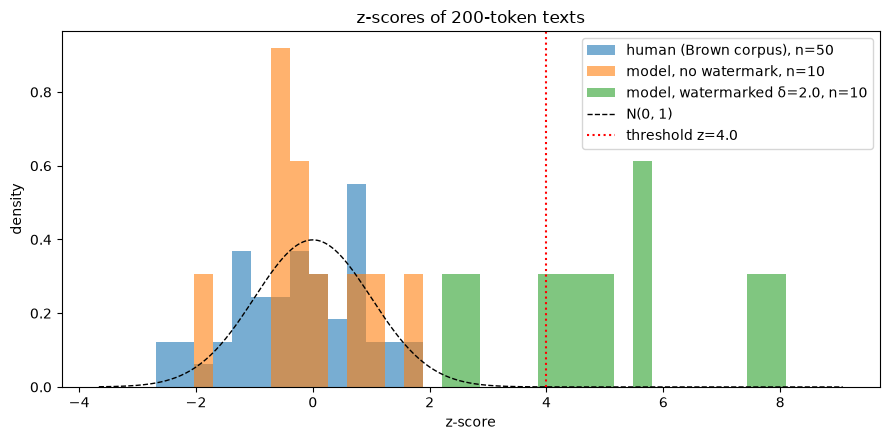

False-positive rate (human): 0.0% | (model, no watermark): 0.0% | detection rate (watermarked): 70.0%


In [16]:
plain_gens = generate_many(PROMPTS, None)
wm_gens = generate_many(PROMPTS, baseline)

z_human = [detect(t, baseline)["z"] for t in HUMAN_TEXTS]
z_plain = [detect(g["text"], baseline)["z"] for g in plain_gens]
z_wm = [detect(g["text"], baseline)["z"] for g in wm_gens]

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(min(z_human + z_plain + z_wm) - 1, max(z_human + z_plain + z_wm) + 1, 40)
ax.hist(z_human, bins=bins, alpha=0.6, density=True, label=f"human (Brown corpus), n={len(z_human)}")
ax.hist(z_plain, bins=bins, alpha=0.6, density=True, label=f"model, no watermark, n={len(z_plain)}")
ax.hist(z_wm, bins=bins, alpha=0.6, density=True, label=f"model, watermarked δ={DELTA}, n={len(z_wm)}")
xs = np.linspace(bins[0], bins[-1], 300)
ax.plot(xs, norm.pdf(xs), "k--", lw=1, label="N(0, 1)")
ax.axvline(Z_THRESHOLD, color="red", ls=":", label=f"threshold z={Z_THRESHOLD}")
ax.set_xlabel("z-score"); ax.set_ylabel("density"); ax.legend(); ax.set_title(f"z-scores of {MAX_NEW_TOKENS}-token texts")
plt.tight_layout(); plt.show()

print(f"False-positive rate (human): {np.mean(np.array(z_human) > Z_THRESHOLD):.1%} | "
      f"(model, no watermark): {np.mean(np.array(z_plain) > Z_THRESHOLD):.1%} | "
      f"detection rate (watermarked): {np.mean(np.array(z_wm) > Z_THRESHOLD):.1%}")

Human texts and the model's unwatermarked texts both follow N(0, 1) closely, and none comes near the threshold: without the key, text behaves like chance, whoever wrote it. The watermarked texts are clearly shifted to the right but spread widely, from z ≈ 2.2 to 8.1, because some prompts lead to confident, low-entropy text that leaves little room for the watermark (Part 3). 7-8 of 10 watermarked texts pass z > 4; the misses are still far above typical unwatermarked text but don't meet the strict standard. In this small sample a threshold around 2.2 would separate the groups perfectly, but its theoretical false-positive rate is about 1 in 70 texts, so thresholds must come from the null distribution, not from a small sample.

## 2.3 How much text do we need?

We generate a few long watermarked texts and compute z on growing prefixes. The z-score of watermarked text grows roughly like $\sqrt{T}$, while human text stays near zero, so the length at which the curve crosses the threshold tells us the minimum text length for reliable detection at this δ.

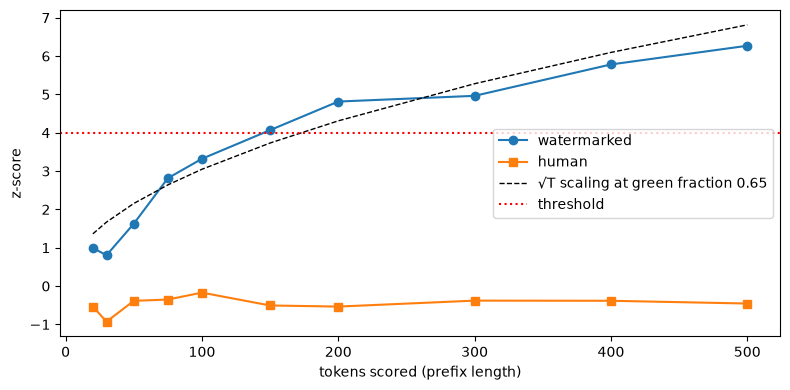

In [17]:
long_gens = generate_many(PROMPTS[:N_LONG], baseline, max_new_tokens=LONG_TOKENS)
long_human = load_human_texts(N_LONG, LONG_TOKENS)
prefix_lengths = [L for L in [20, 30, 50, 75, 100, 150, 200, 300, 400, 500] if L <= LONG_TOKENS]

def z_on_prefixes(texts: list[str]) -> np.ndarray:
    out = []
    for text in texts:
        ids = tokenizer.encode(text, add_special_tokens=False)
        out.append([detect(tokenizer.decode(ids[:L]), baseline)["z"] for L in prefix_lengths])
    return np.array(out, dtype=float)

zl_wm, zl_human = z_on_prefixes([g["text"] for g in long_gens]), z_on_prefixes(long_human)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(prefix_lengths, np.nanmean(zl_wm, 0), "o-", label="watermarked")
ax.plot(prefix_lengths, np.nanmean(zl_human, 0), "s-", label="human")
f = np.nanmean([detect(g["text"], baseline)["green_fraction"] for g in long_gens])
ref = (f - GAMMA) * np.sqrt(np.array(prefix_lengths)) / math.sqrt(GAMMA * (1 - GAMMA))
ax.plot(prefix_lengths, ref, "k--", lw=1, label=f"√T scaling at green fraction {f:.2f}")
ax.axhline(Z_THRESHOLD, color="red", ls=":", label="threshold")
ax.set_xlabel("tokens scored (prefix length)"); ax.set_ylabel("z-score"); ax.legend()
plt.tight_layout(); plt.show()

Averaged over three long texts, the watermarked z-score grows roughly like √T, from about 1 at 20 tokens to about 6.3 at 500, crossing z = 4 at around 150 tokens. Human text stays between about −1 and 0 at every length, so longer human texts do not drift toward the threshold. The curve wiggles because the green fraction varies along a text: confident, predictable stretches add tokens without adding green ones. With a green fraction of 0.65, reaching z = 4 takes about (2 / 0.15)² ≈ 178 tokens; since the required length depends on the square of the green excess, a slightly stronger watermark or a less confident model would shorten it considerably. For this model at δ = 2, 150–200 tokens is the practical minimum.

# Part 3: The knobs — δ, γ and entropy

## 3.1 The best case, in theory

At a position where the model is completely undecided, the watermark gets its best chance. The curve below is $P(\text{green}) = \gamma e^{\delta} / (\gamma e^{\delta} + 1 - \gamma)$, an upper bound on the green fraction we can hope to observe.

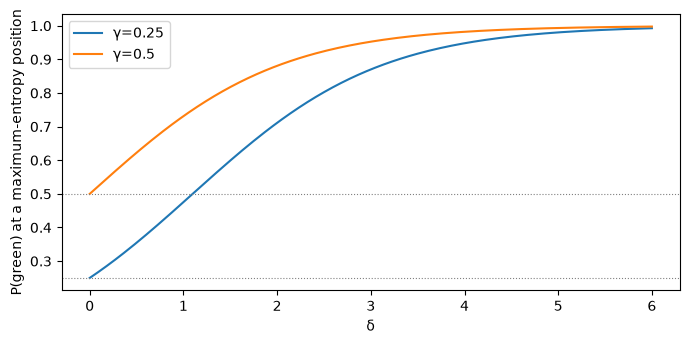

In [18]:
d = np.linspace(0, 6, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
for g in [0.25, 0.5]:
    ax.plot(d, g * np.exp(d) / (g * np.exp(d) + 1 - g), label=f"γ={g}")
    ax.axhline(g, lw=0.8, ls=":", color="grey")
ax.set_xlabel("δ"); ax.set_ylabel("P(green) at a maximum-entropy position"); ax.legend()
plt.tight_layout(); plt.show()

## 3.2 The watermark lives in high-entropy positions

During generation the processor recorded the entropy of the model's original distribution at every step. We group the generated tokens by that entropy and check how often each group is green. Low-entropy positions should stay near γ; high-entropy positions should approach the curve above.

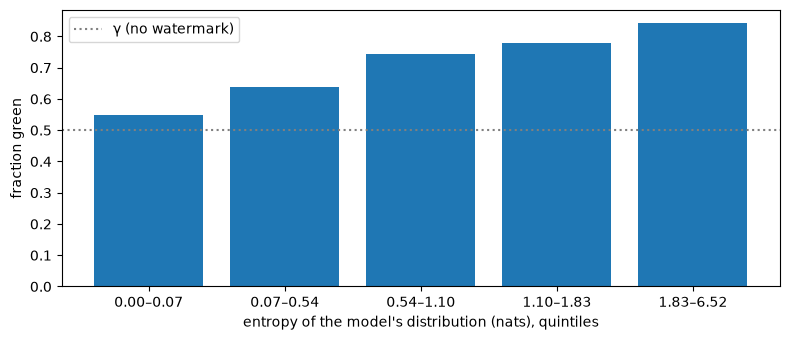

In [19]:
entropies, greens = [], []
for g in wm_gens:
    full = g["prompt_ids"] + g["ids"]
    flags, _ = score_tokens(full, baseline)
    comp_flags = flags[-len(g["ids"]):]
    n = min(len(comp_flags), len(g["entropies"]))
    entropies += g["entropies"][:n]
    greens += comp_flags[:n]

ent_df = pd.DataFrame(dict(entropy=entropies, green=greens))
ent_df["bin"] = pd.qcut(ent_df["entropy"], q=5, duplicates="drop")
summary = ent_df.groupby("bin", observed=True)["green"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar([f"{max(iv.left, 0):.2f}–{iv.right:.2f}" for iv in summary.index], summary["mean"])
ax.axhline(GAMMA, color="grey", ls=":", label="γ (no watermark)")
ax.set_xlabel("entropy of the model's distribution (nats), quintiles"); ax.set_ylabel("fraction green"); ax.legend()
plt.tight_layout(); plt.show()

The lowest-entropy fifth of positions (below 0.15 nats) is green 49% of the time, exactly γ: there the watermark does nothing. The highest-entropy fifth is green 86% of the time, close to the theoretical maximum of 88% for δ = 2 from 3.1. Notice how confident the model is: 40% of all positions have entropy below 0.7 nats. MiniCPM5-2B is instruction-tuned, and such models are much more certain than the base models used in [the original paper](https://arxiv.org/abs/2301.10226), so the same δ produces a weaker watermark. That explains the moderate z-scores throughout this notebook; it is not a bug.

## 3.3 Quality versus detectability

We sweep δ (and try γ = 0.25 once), generate the same prompts, and measure two things: the mean z-score (detectability) and the perplexity of the generated text under the same model (a rough quality proxy; higher means the watermark pushed the model further from what it wanted to say). [The paper](https://arxiv.org/abs/2301.10226) uses a larger "oracle" model for perplexity; using the generator itself is cheaper and fine for comparing settings with each other.

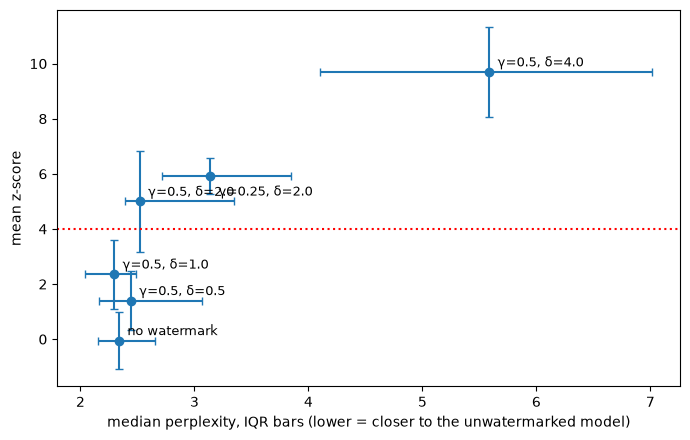

,z_mean,z_std,ppl_q25,ppl_median,ppl_q75
setting,,,,,
no watermark,-0.05,1.04,2.16,2.34,2.66
"γ=0.5, δ=0.5",1.40,1.07,2.16,2.44,3.06
"γ=0.5, δ=1.0",2.36,1.25,2.04,2.30,2.49
"γ=0.5, δ=2.0",5.00,1.83,2.39,2.52,3.35
"γ=0.5, δ=4.0",9.70,1.63,4.10,5.59,7.01
"γ=0.25, δ=2.0",5.92,0.66,2.72,3.14,3.84


In [20]:
@torch.no_grad()
def perplexity(prompt_ids: list[int], completion_ids: list[int]) -> float:
    ids = torch.tensor([prompt_ids + completion_ids], device=model.device)
    logits = model(ids).logits[0, :-1].float()
    logp = torch.log_softmax(logits, -1).gather(1, ids[0, 1:, None])[:, 0]
    return float(torch.exp(-logp[len(prompt_ids) - 1:].mean()))

settings = [("no watermark", None)]
settings += [(f"γ=0.5, δ={d}", WatermarkLogitsProcessor(LeftHash(), gamma=0.5, delta=d)) for d in DELTAS]
settings += [(f"γ=0.25, δ={DELTA}", WatermarkLogitsProcessor(LeftHash(), gamma=0.25, delta=DELTA))]

rows = []
for label, proc in settings:
    for g in generate_many(PROMPTS, proc):
        z = detect(g["text"], proc or baseline)["z"]
        rows.append(dict(setting=label, z=z, ppl=perplexity(g["prompt_ids"], g["ids"])))
# Perplexity has heavy tails (one degenerate sample can explode it), so we report median and interquartile range
sweep = pd.DataFrame(rows).groupby("setting", sort=False).agg(
    z_mean=("z", "mean"), z_std=("z", "std"),
    ppl_q25=("ppl", lambda x: x.quantile(0.25)), ppl_median=("ppl", "median"), ppl_q75=("ppl", lambda x: x.quantile(0.75)))

fig, ax = plt.subplots(figsize=(7, 4.5))
xerr = [sweep["ppl_median"] - sweep["ppl_q25"], sweep["ppl_q75"] - sweep["ppl_median"]]
ax.errorbar(sweep["ppl_median"], sweep["z_mean"], xerr=xerr, yerr=sweep["z_std"], fmt="o", capsize=3)
for k, (label, r) in enumerate(sweep.iterrows()):
    offset = (6, -14) if label.startswith("γ=0.25") else (6, 4)
    ax.annotate(label, (r["ppl_median"], r["z_mean"]), textcoords="offset points", xytext=offset, fontsize=9)
ax.axhline(Z_THRESHOLD, color="red", ls=":")
ax.set_xlabel("median perplexity, IQR bars (lower = closer to the unwatermarked model)"); ax.set_ylabel("mean z-score")
plt.tight_layout(); plt.show()
sweep.round(2)

Detectability grows steadily with δ: the mean z goes from 1.4 at δ = 0.5 to 2.4, 5.0 and 9.7 at δ = 1, 2 and 4. The quality cost is not linear. Up to δ = 1 the median perplexity stays within noise of the unwatermarked 2.34; at δ = 2 it rises only to 2.52, but at δ = 4 it more than doubles (5.59), meaning the watermark regularly overrides the model's preferred word. δ = 2 is the best compromise here, though its large spread (std 1.83) means some texts still fall below z = 4. Shrinking the green list to γ = 0.25 at δ = 2 gives stronger and much more consistent detection (z = 5.9, std 0.66), because each green token is rarer under chance and so counts as stronger evidence, but it costs more quality (median perplexity 3.14, +34%). With 10 prompts, differences of a few tenths are within noise.

# Part 4: Attacks and an evaluation harness

A watermark is only useful if it survives what people actually do with text: edit it, swap words, or ask another model to rewrite it. To compare variants fairly we need attacks that really do what their names say, applied only to the generated text, on texts long enough for the test to mean something.

**Three attacks**

* **WordNet noise.** Pick a fraction of the words and replace each with the first WordNet lemma that differs, whatever its part of speech. This often yields nonsense ("have" → "rich person", "in" → "inch"), so it measures robustness to **random lexical noise**, not to paraphrasing.
* **Synonym swap.** A meaning-preserving edit: only singular nouns, adjectives and adverbs are replaced, only with single-word synonyms that have the same part of speech, and capitalization and punctuation are kept. Grammar stays intact, but not every word has a usable synonym, so the achieved edit rate can be lower than requested.
* **LLM paraphrase.** The same model, *without* the watermark, rewrites the whole text. This is the realistic strong attack.

Because requested and achieved edit rates differ, every result records the **realized edit fraction**: one minus the word-level similarity between the original and the attacked text.

In [21]:
from nltk.corpus import stopwords
from nltk.corpus import wordnet as wn

STOPWORDS = set(stopwords.words("english")) # Common English words ("the", "is", "of")
WORD_RE = re.compile(r"[A-Za-z]+")  # Defines what counts as a word
POS_MAP = {"NN": wn.NOUN, "JJ": wn.ADJ, "RB": wn.ADV}  # exact tags only: no plurals, no verbs, no proper nouns


def _match_case(src: str, repl: str) -> str:
    """Preserve capitalization of the original word onto its replacement"""
    if src.isupper() and len(src) > 1:
        return repl.upper()
    return repl[0].upper() + repl[1:] if src[0].isupper() else repl


def _replace_words(text: str, replacements: dict[int, str]) -> str:
    """Rebuilds the text with some words swapped, keeping punctuation and layout intact"""
    out, last = [], 0
    for i, m in enumerate(WORD_RE.finditer(text)):
        out.append(text[last:m.start()])
        out.append(replacements.get(i, m.group()))
        last = m.end()
    out.append(text[last:])
    return "".join(out)


def edit_fraction(original: str, attacked: str) -> float:
    """Measures how much an attack changed the text
       Returns one minus similarity: 0 means unchanged, 0.3 means about 30% of the words differ
    """
    return 1 - difflib.SequenceMatcher(None, original.split(), attacked.split(), autojunk=False).ratio()


def attack_wordnet_noise(text: str, rate: float, seed: int = SEED) -> str:
    """Random word noise
       It uses any meaning of any part of speech, so results are often nonsense:
       "have" becomes "rich person", "in" becomes "inch".
    """
    rng = random.Random(seed)
    words = [m.group() for m in WORD_RE.finditer(text)]
    replacements = {}
    for i in rng.sample(range(len(words)), int(round(rate * len(words)))):
        for syn in wn.synsets(words[i]):
            names = [l.name() for l in syn.lemmas() if l.name().lower() != words[i].lower()]
            if names:
                replacements[i] = _match_case(words[i], names[0].replace("_", " "))
                break
    return _replace_words(text, replacements)


def _best_synonym(word: str, pos) -> str | None:
    """Meaning-preserving swaps
       Looks only at the word's first two WordNet meanings of the requested part of speech, the most common senses
       keeps single words made only of letters hat differ from the original,
       and picks the one with the highest lemma.count()
    """
    best, best_count = None, -1
    for syn in wn.synsets(word, pos=pos)[:2]:
        for lemma in syn.lemmas():
            name = lemma.name()
            if name.isalpha() and name.lower() != word.lower() and lemma.count() > best_count:
                best, best_count = name, lemma.count()
    return best


def attack_synonym_swap(text: str, rate: float, seed: int = SEED) -> str:
    """Tags every word with its part of speech using nltk.pos_tag
       Builds a list of candidates: words with an allowed tag
       Picks rate * number of words candidates at random and rebuilds the text
    """
    rng = random.Random(seed)
    words = [m.group() for m in WORD_RE.finditer(text)]
    candidates = {}
    for i, (word, tag) in enumerate(nltk.pos_tag(words)):
        pos = POS_MAP.get(tag)
        if pos is None or len(word) < 3 or word.lower() in STOPWORDS:
            continue
        syn = _best_synonym(word.lower(), pos)
        if syn:
            candidates[i] = _match_case(word, syn)
    k = min(len(candidates), int(round(rate * len(words))))
    chosen = rng.sample(sorted(candidates), k)
    return _replace_words(text, {i: candidates[i] for i in chosen})


PARAPHRASE_SAMPLING = dict(do_sample=True, temperature=0.7, top_p=0.9, top_k=0)

def paraphrase_many(texts: list[str], seeds: list[int] | None = None) -> list[str]:
    """Asks the model itself, without the watermark, to rewrite each text
       It models a realistic attacker who rewrites the text with a tool that doesn't know the key.
    """
    seeds = [SEED + i for i in range(len(texts))] if seeds is None else seeds
    prompts, caps = [], []
    for text in texts:
        instruction = ("Paraphrase the following text. Keep the meaning, but use different words and sentence "
                       "structure. Reply with the paraphrased text only.\n\n" + text)
        if tokenizer.chat_template:
            prompts.append(tokenizer.apply_chat_template([{"role": "user", "content": instruction}], tokenize=False,
                                                         add_generation_prompt=True, enable_thinking=False))
        else:
            prompts.append(instruction + "\n\nParaphrase:")
        caps.append(int(1.3 * len(tokenizer.encode(text, add_special_tokens=False))) + 20)
    add_special = not tokenizer.chat_template  # the chat template already adds BOS
    gens = generate_many(prompts, None, max_new_tokens=caps, seeds=seeds, sampling=PARAPHRASE_SAMPLING,
                         force_length=False, add_special_tokens=add_special)
    return [re.sub(r"<think>.*?</think>", "", g["text"], flags=re.S).strip() for g in gens]


def attack_llm_paraphrase(text: str, rate: float = 1.0, seed: int = SEED) -> str:
    return paraphrase_many([text], [seed])[0]

In [22]:
# Simple visual sanity check
sample = wm_gens[0]["text"]
print("ORIGINAL\n", sample[:400], "\n")
for name, fn in [("WordNet noise 30%", attack_wordnet_noise), ("Synonym swap 30%", attack_synonym_swap)]:
    attacked = fn(sample, 0.3)
    print(f"{name} (realized edit fraction {edit_fraction(sample, attacked):.2f})\n", attacked[:400], "\n")
if RUN_LLM_PARAPHRASE:
    attacked = attack_llm_paraphrase(sample)
    print(f"LLM paraphrase (realized edit fraction {edit_fraction(sample, attacked):.2f})\n", attacked[:400])

ORIGINAL
  transformative changes to our technology and society. As AI becomes more prevalent, it's important to be aware of its potential impacts on different sectors. By understanding the benefits and limitations of AI, we can make informed decisions about its use. It's also important to consider the ethical and social implications of AI, such as data privacy and bias. As we continue to develop AI, it's c 

WordNet noise 30% (realized edit fraction 0.24)
  transformative change to our engineering and society. Arsenic ARMY INTELLIGENCE becomes more prevailing, it's of import to be aware of its potential impact on unlike sectors. Past understanding the benefits and limitations of AI, we tin make informed decisions astir its use. It's also important to consider the ethical and social implications of AI, such as data privacy and prejudice. Arsenic we g 

Synonym swap 30% (realized edit fraction 0.15)
  transformative changes to our engineering and club. As AI becomes more prevailing, it'

## 4.1 The harness

`run_harness` takes a dictionary of watermark processors and, for each one, generates the same prompts with the same seeds (as one batch), applies every attack at every rate, and runs the detector on the attacked text. It returns one tidy table, so every variant in Part 5 is evaluated in exactly the same way. `length_rate_grid` reuses the same generations, truncated to shorter lengths, to reproduce the length × edit-rate heatmap. The heatmap uses the WordNet-noise attack because it reaches every requested rate; the synonym swap runs out of replaceable words at around 20–25% of the text.

In [23]:
ATTACKS = {"WordNet noise": attack_wordnet_noise, "Synonym swap": attack_synonym_swap}


def run_harness(processors: dict[str, WatermarkLogitsProcessor], prompts=PROMPTS, rates=RATES,
                llm_paraphrase: bool = RUN_LLM_PARAPHRASE):
    rows, gens = [], {}
    for name, proc in processors.items():
        seeds = [SEED + pi for pi in range(len(prompts))]
        batch = generate_many(prompts, proc, seeds=seeds)
        paraphrases = paraphrase_many([g["text"] for g in batch], seeds) if llm_paraphrase else None
        for pi, g in enumerate(batch):
            gens[(name, pi)] = g
            for attack_name, fn in ATTACKS.items():
                for rate in rates:
                    attacked = fn(g["text"], rate, seed=SEED + pi)
                    rows.append(dict(scheme=name, prompt=pi, attack=attack_name, rate=rate,
                                     edit=edit_fraction(g["text"], attacked), **detect(attacked, proc)))
            if llm_paraphrase:
                attacked = paraphrases[pi]
                rows.append(dict(scheme=name, prompt=pi, attack="LLM paraphrase", rate=1.0,
                                 edit=edit_fraction(g["text"], attacked), **detect(attacked, proc)))
    return pd.DataFrame(rows), gens


def length_rate_grid(gens, processors, lengths=HEATMAP_LENGTHS, rates=RATES, attack=attack_wordnet_noise):
    """Reuses the generated texts to show how length and editing interact"""
    grids = {}
    for name, proc in processors.items():
        grid = np.full((len(lengths), len(rates)), np.nan)
        for li, L in enumerate(lengths):
            for ri, rate in enumerate(rates):
                zs = []
                for (scheme, pi), g in gens.items():
                    if scheme == name:
                        truncated = tokenizer.decode(g["ids"][:L], skip_special_tokens=True)
                        zs.append(detect(attack(truncated, rate, seed=SEED + pi), proc)["z"])
                grid[li, ri] = np.nanmean(zs)
        grids[name] = grid
    return grids


def plot_attack_curves(df: pd.DataFrame):
    """Draws the harness results as line plots, one panel per attack.
       Each line is one scheme, showing its mean z-score against the realized edit fraction.
    """
    fig, axes = plt.subplots(1, len(ATTACKS), figsize=(6 * len(ATTACKS), 4.2), sharey=True)
    for ax, attack in zip(np.atleast_1d(axes), ATTACKS):
        sub = df[df.attack == attack]
        for scheme, s in sub.groupby("scheme", sort=False):
            agg = s.groupby("rate").agg(edit=("edit", "mean"), z=("z", "mean"), z_std=("z", "std"))
            ax.errorbar(agg["edit"], agg["z"], yerr=agg["z_std"], marker="o", capsize=3, label=scheme)
        ax.axhline(Z_THRESHOLD, color="red", ls=":")
        ax.set_title(attack); ax.set_xlabel("realized edit fraction"); ax.grid(alpha=0.3)
    np.atleast_1d(axes)[0].set_ylabel("z-score (mean ± std over prompts)")
    np.atleast_1d(axes)[-1].legend(fontsize=8)
    plt.tight_layout(); plt.show()


def plot_heatmaps(grids: dict, lengths=HEATMAP_LENGTHS, rates=RATES):
    """Draws the grids from length_rate_grid as colored heatmaps, one per scheme,
       side by side on a shared color scale, with the z-score written in each cell.
    """
    vmax = np.nanmax([np.nanmax(g) for g in grids.values()])
    fig, axes = plt.subplots(1, len(grids), figsize=(4.2 * len(grids), 3.8), squeeze=False)
    for ax, (name, grid) in zip(axes[0], grids.items()):
        im = ax.imshow(grid, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=vmax)
        for (i, j), v in np.ndenumerate(grid):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if v < vmax / 2 else "black")
        ax.set_xticks(range(len(rates)), rates); ax.set_yticks(range(len(lengths)), lengths)
        ax.set_title(name, fontsize=9); ax.set_xlabel("WordNet-noise rate (requested)")
    axes[0][0].set_ylabel("text length (tokens)")
    fig.colorbar(im, ax=axes[0].tolist(), label="mean z-score")
    plt.show()

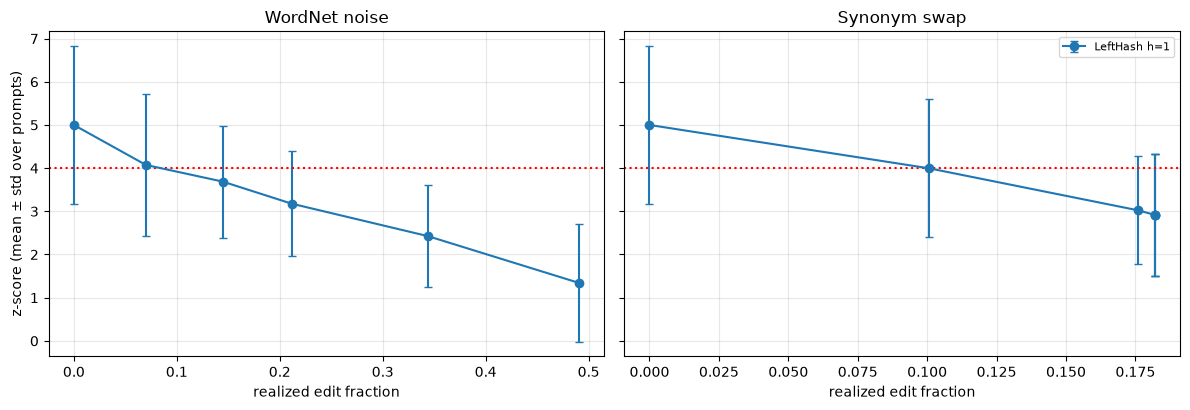

edit     z  detected
attack         rate                      
LLM paraphrase 1.0   0.63  0.03       0.0
Synonym swap   0.0   0.00  5.00       0.7
               0.1   0.10  4.00       0.6
               0.2   0.18  3.02       0.2
               0.3   0.18  2.92       0.2
               0.5   0.18  2.92       0.2
               0.7   0.18  2.92       0.2
WordNet noise  0.0   0.00  5.00       0.7
               0.1   0.07  4.07       0.4
               0.2   0.14  3.69       0.3
               0.3   0.21  3.18       0.3
               0.5   0.34  2.43       0.2
               0.7   0.49  1.34       0.0

In [24]:
baseline_df, baseline_gens = run_harness({"LeftHash h=1": baseline})
plot_attack_curves(baseline_df)
baseline_df.groupby(["attack", "rate"]).agg(edit=("edit", "mean"), z=("z", "mean"),
                                            detected=("is_watermarked", "mean")).round(2)

Without attacks the baseline reaches z = 5.0 on average and 7 of 10 texts are detected, so there is little margin to spare. Word edits wear the watermark down gradually rather than all at once: with WordNet noise, z falls from 5.0 to 4.1, 3.2 and 1.3 at 7%, 21% and 49% of words changed, and detection drops to 40% after only 7%. This smooth decline fits the one-token context, where each edit re-randomizes only its own position and the next. The synonym swap does more damage per edit (z = 4.0 at 10%, 2.9 at 18%), because it targets nouns, adjectives and adverbs, the high-entropy positions where the watermark lives, while random noise also hits function words that carry almost no signal. After the heavier edits z stays well above chance but below the strict threshold. The LLM paraphrase changes 63% of the words and brings z to 0.03, erasing the watermark completely. The synonym swap tops out at about 18% because only some words have usable synonyms.

# Part 5: Changing the context scheme

## 5.1 What a single edit actually breaks

With $h = 1$, changing the token at position $j$ has a **local** effect, not a cascading one. The new token at $j$ is scored against an unchanged context, so it is green by chance (probability γ). The token at $j+1$ gets a new seed, so its green list is re-randomized. Position $j+2$ onward is untouched, because its context no longer contains $j$. So one edit costs at most two scored positions. With a context of $h$ tokens, the edited token sits in the context of the next $h$ positions, so one edit re-randomizes up to $h$ seeds plus its own position.

That is the lever every scheme below pulls: a larger context gives more distinct green lists, which makes them harder for an attacker to learn, but each edit breaks more seeds. The schemes differ in how they turn a window of $h = 3$ tokens into a seed.

## 5.2 Four seeding schemes

| Scheme | Seed | Idea |
|---|---|---|
| **LeftHash h=1** | $\mathrm{PRF}_K(s_{t-1})$ | Baseline. At most $\lvert V \rvert$ distinct green lists. |
| **N-gram hash h=3** | $\mathrm{PRF}_K(s_{t-3}, s_{t-2}, s_{t-1})$ | Up to $\lvert V \rvert^3$ green lists, but an edit anywhere in the window changes the seed. |
| **Min-hash h=3** | $\min_{i=1..3} \mathrm{PRF}_K(s_{t-i})$ | From [Kirchenbauer et al. (2023b)](https://arxiv.org/abs/2306.04634). The seed depends only on the token with the smallest hash, so editing any *other* token in the window leaves it unchanged. |
| **SimHash h=3, 16 bit** | $\mathrm{PRF}_K(\text{signature})$ | Average the window's token embeddings and keep the sign of 16 secret random projections. Similar embedding vectors tend to get the same signature. |

**SimHash in one paragraph.** SimHash ([Charikar, 2002](https://doi.org/10.1145/509907.509965)) is a *locality-sensitive hash* (LSH): unlike a cryptographic hash, it is designed so that similar inputs collide. Draw $b$ random vectors $w_1, \dots, w_b$ and map a vector $x$ to the bits $\mathbb{1}[w_i \cdot x > 0]$. Each bit is a random hyperplane cutting the space in half. Two vectors at angle $\theta$ agree on each bit with probability $1 - \theta/\pi$, so vectors pointing in similar directions usually get the same signature. We keep the projections secret by deriving them from the key. Two caveats: these are the model's *static input* embeddings, averaged over three tokens, not a contextual sentence meaning; and a 16-bit signature allows at most $2^{16}$ distinct green lists.

**One more difference: the detector.** LeftHash, N-gram hash and Min-hash need only the key and the tokenizer. SimHash also needs the model's embedding matrix at detection time.

In [ ]:
EMBEDDINGS = model.get_input_embeddings()


def _signature(context: list[int], W: torch.Tensor) -> int:
    """Turns the context tokens into a 16-bit number: average their embeddings,
       keep the sign of each secret projection
    """
    with torch.no_grad():
        ids = torch.tensor(context, device=EMBEDDINGS.weight.device)
        mean = EMBEDDINGS(ids).float().mean(0).cpu()
    bits = (W @ mean > 0).tolist()
    return sum(int(b) << i for i, b in enumerate(bits))


class NGramHash(SeedingScheme):
    """Seed from the exact last 3 tokens, in order: very few repeated green lists,
       but any edit in the window changes it
    """
    name = "N-gram hash h=3"
    context_width = 3

    def seed(self, context):
        return prf(*context)


class MinHash(SeedingScheme):
    """Seed from the one token with the smallest hash among the last 3: 
       editing the other tokens leaves it unchanged
    """
    name = "Min-hash h=3"
    context_width = 3

    def seed(self, context):
        return min(prf(t) for t in context)


class SimHashSignature(SeedingScheme):
    """Seed from the rough meaning of the last 3 tokens (16-bit SimHash signature);
       the detector also needs the embeddings
    """
    name = "SimHash h=3 (16 bit)"
    context_width = 3
    needs_model = True

    def __init__(self, bits: int = 16):
        g = torch.Generator().manual_seed(prf(0x51A) % 2**63)  # projections derived from the secret key
        self.W = torch.randn(bits, EMBEDDINGS.embedding_dim, generator=g)

    def seed(self, context):
        return prf(_signature(context, self.W), 0x51B)


SCHEMES = [LeftHash(), NGramHash(), MinHash(), SimHashSignature()]
PROCESSORS = {s.name: WatermarkLogitsProcessor(s, gamma=GAMMA, delta=DELTA) for s in SCHEMES}

## 5.3 Seeds broken by one edit

A direct test of 5.1. We take the watermarked baseline texts, pick random positions, and replace one token in two ways: with a random token, and with its **nearest neighbour** in the model's embedding space (the smallest possible "semantic" edit). For each scheme we count how many of the following $h$ positions get a different seed. The edited position itself is lost in every scheme and is not counted.

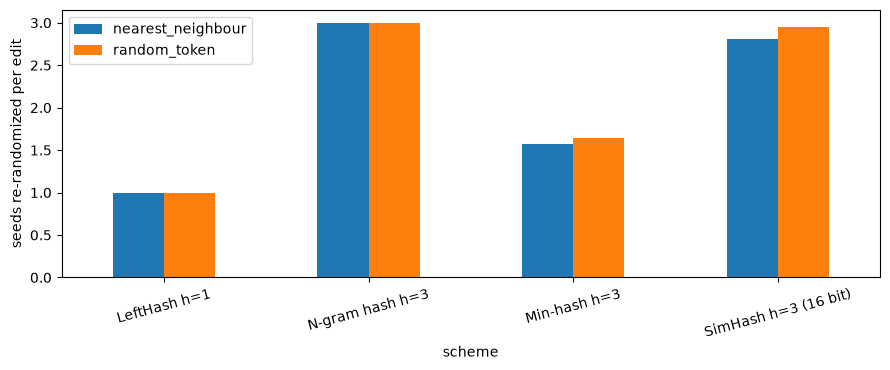

,nearest_neighbour,random_token
scheme,,
LeftHash h=1,1.00,1.00
N-gram hash h=3,3.00,3.00
Min-hash h=3,1.57,1.64
SimHash h=3 (16 bit),2.81,2.95


In [26]:
@torch.no_grad()
def _embedding_norms(chunk: int = 8192) -> torch.Tensor:
    """Computes the length (norm) of every embedding vector, one number per vocabulary token"""
    W = EMBEDDINGS.weight
    return torch.cat([W[i:i + chunk].float().norm(dim=1).cpu() for i in range(0, W.shape[0], chunk)])

EMB_NORMS = _embedding_norms()

@torch.no_grad()
def nearest_neighbour(tok: int) -> int:
    """Finds the token whose embedding is most similar to the given token's, using cosine similarity"""
    W = EMBEDDINGS.weight
    sims = (W @ W[tok]).float().cpu() / (EMB_NORMS * EMB_NORMS[tok] + 1e-8)
    sims[tok] = -float("inf")
    return int(sims.argmax())


def seeds_broken(ids: list[int], pos: int, new_tok: int, scheme: SeedingScheme) -> int:
    """Counts how many seeds change when position pos is replaced
       The edited position itself isn't counted: its token changed
    """
    h = scheme.context_width
    edited = ids.copy()
    edited[pos] = new_tok
    return sum(scheme.seed(ids[t - h:t]) != scheme.seed(edited[t - h:t]) for t in range(pos + 1, pos + h + 1))


rng = random.Random(SEED)
edits = []
for _ in range(N_EDITS):
    ids = rng.choice(wm_gens)["ids"]
    pos = rng.randrange(3, len(ids) - 4)
    edits.append((ids, pos, nearest_neighbour(ids[pos]), rng.randrange(len(tokenizer))))

broken = pd.DataFrame([
    dict(scheme=s.name,
         nearest_neighbour=np.mean([seeds_broken(ids, pos, nn, s) for ids, pos, nn, _ in edits]),
         random_token=np.mean([seeds_broken(ids, pos, rt, s) for ids, pos, _, rt in edits]))
    for s in SCHEMES]).set_index("scheme")

broken.plot.bar(figsize=(9, 3.8), rot=15, ylabel="seeds re-randomized per edit")
plt.tight_layout(); plt.show()
broken.round(2)

LeftHash and the N-gram hash lose exactly 1 and 3 seeds per edit, whatever the replacement. Min-hash loses about 1.6: a window's seed changes only if the edited token was the one with the smallest hash or its replacement becomes the smallest, which happens about 5/9 of the time (3 × 5/9 ≈ 1.67). Only SimHash reacts to the kind of edit: nearest-neighbour replacements break 2.81 seeds against 2.95 for random tokens. That gap is the robustness the semantic signature buys, and it is small: even the closest possible replacement kept all 16 bits in only about 6% of the affected windows.

## 5.4 All schemes through the harness

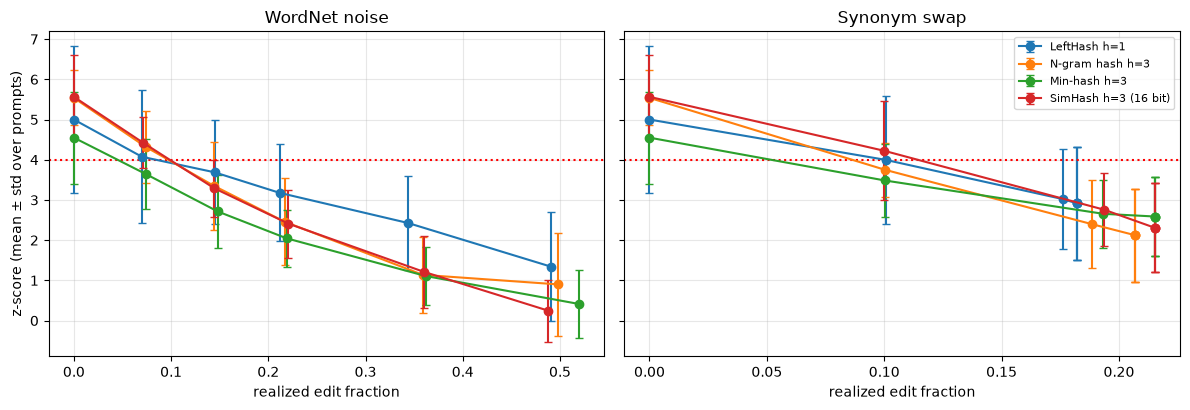

In [27]:
comparison_df, comparison_gens = run_harness(PROCESSORS)
plot_attack_curves(comparison_df)

**What we test.** How quickly each seeding scheme loses detectability as more of the text is edited, under two kinds of word-level edits: random noise and meaning-preserving synonym swaps.

Robustness is decided by how many positions a single edit destroys. Schemes that look at three tokens (N-gram hash, SimHash) lose about twice as much evidence per edit as LeftHash, so after the first few percent of edits LeftHash stays the most detectable. Min-hash breaks fewer seeds per edit than the 3-token schemes, but in practice it gains little over them and does not beat LeftHash. SimHash behaves like the N-gram hash even under synonym swaps, the attack it was designed for: a 16-bit signature over static embeddings is too sensitive to survive real word changes. Meaning-preserving edits are more damaging than random noise, because they hit exactly the words where the model had a choice and the watermark lives. For every scheme, changing about 10% of the words brings a 200-token text down to the detection threshold.

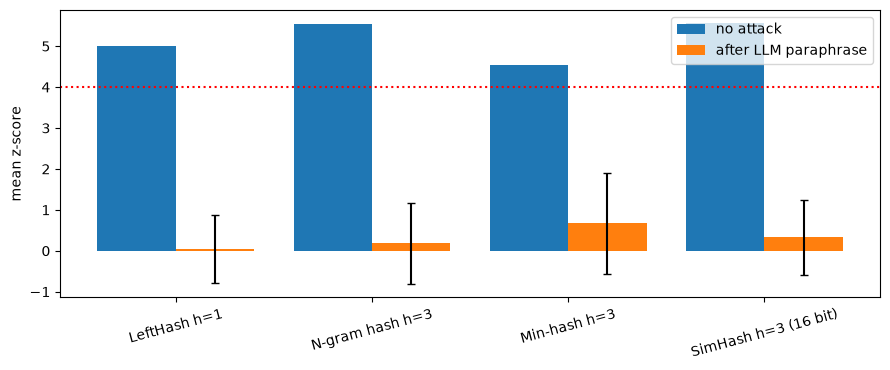

In [28]:
if RUN_LLM_PARAPHRASE:
    para = comparison_df[comparison_df.attack == "LLM paraphrase"].groupby("scheme", sort=False)["z"].agg(["mean", "std"])
    clean = comparison_df[(comparison_df.attack == "Synonym swap") & (comparison_df.rate == 0.0)].groupby("scheme", sort=False)["z"].mean()
    x = np.arange(len(para))
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.bar(x - 0.2, clean[para.index], 0.4, label="no attack")
    ax.bar(x + 0.2, para["mean"], 0.4, yerr=para["std"], capsize=3, label="after LLM paraphrase")
    ax.axhline(Z_THRESHOLD, color="red", ls=":")
    ax.set_xticks(x, para.index, rotation=15); ax.set_ylabel("mean z-score"); ax.legend()
    plt.tight_layout(); plt.show()

**What we test.** Whether any of the schemes survives the realistic strong attack: a full rewrite of the text by a language model that does not know the key.

None does. After a paraphrase, all four schemes score like unwatermarked text. Every scheme ties the watermark to exact tokens and their order, and a paraphrase changes both, so no choice of context window can protect against it. Surviving paraphrasing requires watermarks defined on meaning rather than on tokens, such as the sentence-level semantic watermarks [SemStamp](https://arxiv.org/abs/2310.03991) or [SIR](https://arxiv.org/abs/2310.06356).

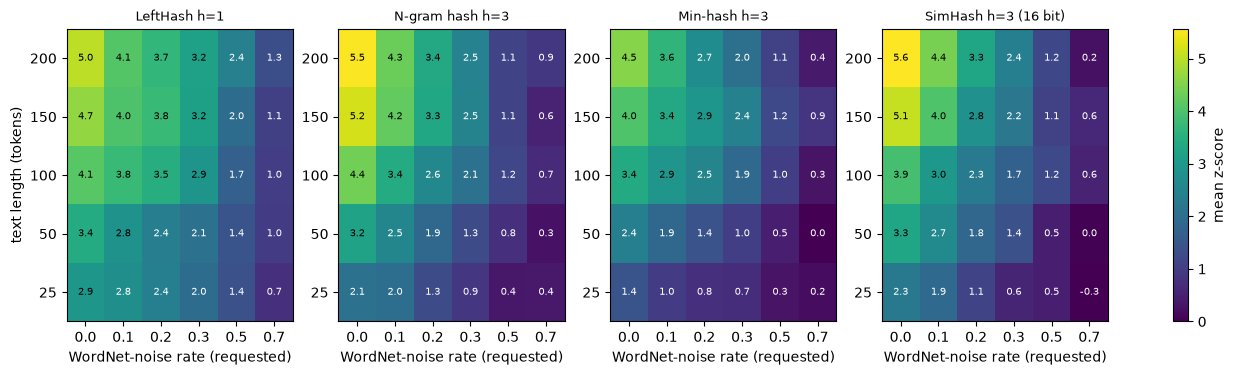

In [29]:
grids = length_rate_grid(comparison_gens, PROCESSORS)
plot_heatmaps(grids)

**What we test.** How text length and the amount of editing interact: whether longer texts can compensate for edits.

Length compensates only for light editing. As long as a clear excess of green tokens survives, evidence keeps accumulating with every additional token, so a longer text can stay detectable despite some edits. Once heavy editing has removed most of the excess, no amount of text brings it back. In practice, reliable detection needs both enough text (150–200 tokens for this model) and a text that has been edited only lightly. LeftHash tolerates editing best across all lengths, which makes it the most practical choice when robustness matters more than protection against key stealing.

## 5.5 The security side: how often do green lists repeat?

Robustness is only half of the trade-off. An attacker who can query the watermarked model many times can count which tokens appear after which contexts and gradually learn the green lists. With them, the attacker can scrub the watermark or forge it onto human text ("watermark stealing", [Jovanović et al., 2024](https://arxiv.org/abs/2402.19361)). The fewer distinct green lists a scheme uses, the faster this works.

A cheap proxy: over all text generated in the harness, how many generation steps reused a seed that had already been used? We also list the theoretical maximum number of distinct green lists.

In [ ]:
def seed_reuse(scheme: SeedingScheme, gens: list[dict]) -> float:
    """Share of generation steps that reused an already-seen green list (higher = easier to steal)"""
    h, seeds = scheme.context_width, []
    for g in gens:
        full = g["prompt_ids"] + g["ids"]
        # Recompute the seed used at every generated position
        seeds += [scheme.seed(full[t - h:t]) for t in range(len(g["prompt_ids"]), len(full))]
    return 1 - len(set(seeds)) / len(seeds)

# Theoretical maximum number of distinct green lists per scheme
max_lists = {"LeftHash h=1": "|V|", "N-gram hash h=3": "|V|³", "Min-hash h=3": "|V|",
             "SimHash h=3 (16 bit)": "2¹⁶"}

# One summary row per scheme: security, robustness, detection strength and quality side by side
summary_rows = []
for s in SCHEMES:
    gens = [g for (name, _), g in comparison_gens.items() if name == s.name]
    df = comparison_df[comparison_df.scheme == s.name]
    syn = df[df.attack == "Synonym swap"]
    row = dict(scheme=s.name,
               detector_needs="key + tokenizer + embeddings" if s.needs_model else "key + tokenizer",
               max_green_lists=max_lists[s.name],
               seed_reuse=seed_reuse(s, gens),
               seeds_broken_per_nn_edit=broken.loc[s.name, "nearest_neighbour"],
               z_clean=syn[syn.rate == 0.0]["z"].mean(),
               z_synonym_max_rate=syn[syn.rate == max(RATES)]["z"].mean(),
               ppl=np.median([perplexity(g["prompt_ids"], g["ids"]) for g in gens]))
    if RUN_LLM_PARAPHRASE:
        row["z_llm_paraphrase"] = df[df.attack == "LLM paraphrase"]["z"].mean()
    summary_rows.append(row)
pd.DataFrame(summary_rows).set_index("scheme").round(3)

,detector_needs,max_green_lists,seed_reuse,seeds_broken_per_nn_edit,z_clean,z_synonym_max_rate,ppl,z_llm_paraphrase
scheme,,,,,,,,
LeftHash h=1,key + tokenizer,|V|,0.615,1.00,5.000,2.918,2.521,0.034
N-gram hash h=3,key + tokenizer,|V|³,0.044,3.00,5.539,2.123,3.216,0.179
Min-hash h=3,key + tokenizer,|V|,0.784,1.57,4.549,2.588,2.850,0.678
SimHash h=3 (16 bit),key + tokenizer + embeddings,2¹⁶,0.247,2.81,5.565,2.309,2.875,0.325


## 5.6 Reading the results

* **No scheme wins on both robustness and security.** LeftHash loses 1 seed per edit and keeps z = 2.9 after the strongest synonym swap, but 62% of its generation steps reuse a green list it has already used. The N-gram hash reuses only 4%, which makes its green lists far harder to steal, but it loses 3 seeds per edit and falls to z = 2.1 after the same swap. Using more of the context makes green lists rarer and harder to learn, and makes every edit more costly.
* **Min-hash doesn't deliver on its promise here.** It breaks only about 1.6 seeds per edit, yet it stays below LeftHash under every attack (z = 2.6 after the synonym swap) and has the highest reuse of all (78%). In this run it is both less robust and less secure than LeftHash, although part of its gap comes from a lower starting point, which may be noise.
* **A 16-bit SimHash doesn't pay off.** Even the closest possible replacement kept all 16 signature bits in only about 6% of the affected windows (2.81 of 3 seeds broken). Under attack it behaves like the N-gram hash (z = 2.3 vs 2.1 after the synonym swap), while reusing six times as many green lists (25% vs 4%) and requiring the model's embeddings at detection time. Fewer bits would let the signature survive edits more often, at the cost of even more reuse.
* **Length helps only while some signal survives.** At 10% noise, LeftHash rises from z = 2.8 at 50 tokens to 4.1 at 200. At 50–70% noise no scheme reaches z = 2.5 at any length: once the green excess is gone, more tokens cannot bring it back.
* **A full paraphrase defeats every scheme.** After an LLM paraphrase, all four score between z = 0.03 and 0.7, indistinguishable from unwatermarked text. Token-level watermarks store the signal in exact word choice and order, and a paraphrase changes both. Surviving it requires watermarks defined on meaning, such as [SemStamp](https://arxiv.org/abs/2310.03991) and [SIR](https://arxiv.org/abs/2310.06356).
* **Detection strength and quality are similar across schemes.** With the same δ, all schemes start between z = 4.5 and 5.6 and reach a median perplexity between 2.5 and 3.2 (2.34 without a watermark, Part 3.3). With 10 prompts these differences are within noise, and the order of the schemes changed between our runs.

**Bottom line.** For this model and setting, LeftHash offers the best robustness with the simplest detector. The N-gram hash is the better choice when protecting the key against stealing matters more than surviving edits. Neither Min-hash nor SimHash earned its extra complexity in our experiments, and no token-level scheme survives a paraphrase.

# Part 6: Limitations and outlook

**What a detection proves.** A high z-score says the text agrees with our key's green lists far more than chance allows, so a model holding that key was likely involved in producing it. It does not tell us *how much* of the text the model wrote: a human draft lightly edited by the model and a fully generated text can look the same. It says nothing about text from other models, and a low z-score does not prove human authorship.

**Where the signal comes from.** Only tokens the model chose with some freedom carry the mark (Part 3.2). Code, tables, quotations and short answers carry little, and short texts can't reach a meaningful z at all (Part 2.3). This depends strongly on the model: instruction-tuned models like the one used here are far more confident than the base models in [the original paper](https://arxiv.org/abs/2301.10226), so the same δ gives a weaker watermark, and reliable detection needs 150–200 tokens.

**Threat model.** Three kinds of attack matter: *scrubbing* (editing or paraphrasing the mark away, Parts 4–5), *spoofing* (making human text look watermarked), and *stealing* (learning the green lists from many samples, which also enables the other two; see [Jovanović et al., 2024](https://arxiv.org/abs/2402.19361)). Every design choice moves the balance between them: in Part 5, the scheme that survived editing best was among the easiest to steal, and none survived a paraphrase.

**Limits of our experiments.** The results come from one model, one key and 10 prompts, so differences of a few tenths in z are within noise. Perplexity is measured with the generator itself rather than a larger independent model. The paraphrase attack uses the same model without the watermark; a stronger or different paraphraser would, if anything, remove even more of the signal. And green-list reuse is only a proxy for how easily a watermark can be stolen; we did not run an actual stealing attack.

**Next: SynthID-Text.** Instead of adding δ to logits, [SynthID-Text](https://www.nature.com/articles/s41586-024-08025-4) runs a *tournament*: it draws several candidate tokens from the unchanged distribution and lets keyed pseudo-random scores decide the winner. The output distribution stays (nearly) the same, so there is no δ to trade against quality.

## References

1. J. Kirchenbauer, J. Geiping, Y. Wen, J. Katz, I. Miers, T. Goldstein. [A Watermark for Large Language Models](https://arxiv.org/abs/2301.10226). ICML 2023.
2. J. Kirchenbauer et al. [On the Reliability of Watermarks for Large Language Models](https://arxiv.org/abs/2306.04634). ICLR 2024. (Min-hash and other seeding schemes.)
3. S. Dathathri et al. [Scalable watermarking for identifying large language model outputs](https://www.nature.com/articles/s41586-024-08025-4). *Nature* 634, 2024. (SynthID-Text.)
4. M. S. Charikar. [Similarity estimation techniques from rounding algorithms](https://doi.org/10.1145/509907.509965). STOC 2002. (SimHash.)
5. A. Hou et al. [SemStamp: A Semantic Watermark with Paraphrastic Robustness for Text Generation](https://arxiv.org/abs/2310.03991). NAACL 2024.
6. A. Liu et al. [A Semantic Invariant Robust Watermark for Large Language Models](https://arxiv.org/abs/2310.06356). ICLR 2024. (SIR.)
7. N. Jovanović, R. Staab, M. Vechev. [Watermark Stealing in Large Language Models](https://arxiv.org/abs/2402.19361). ICML 2024.